In [1]:
import numpy as np
import pandas as pd
import machinegnostics

# Data Loading and Processing

In [3]:
# read file from the github link
# https://github.com/kamleshparmar17/Advanced_PulseHeatPipe_krp/blob/main/data/database/database.csv
url = "https://raw.githubusercontent.com/kamleshparmar17/Advanced_PulseHeatPipe_krp/main/data/database/database.csv"
db = pd.read_csv(url)
db.head()

,TIME,DATE,TC_1,TC_2,TC_3,TC_4,TC_5,TC_6,TC_7,TC_8,...,P[bar],Te_mean[K],Tc_mean[K],Te_std[K],Tc_std[K],T_pulse[K],TR[K/W],GFE_Te[KJ/mol],GFE_Tc[KJ/mol],dG[KJ/mol]
0,19:02:43,27/03/2025,34.1,34.8,33.9,34.1,34.5,31.8,31.4,31.5,...,0.42,307.43,303.97,273.51,274.64,353.75,0.09,-2232.13,-2207.04,-25.09
1,19:02:44,27/03/2025,34.1,34.8,33.9,34.1,34.5,31.8,31.4,31.5,...,0.42,307.43,303.97,273.51,274.64,353.75,0.09,-2232.13,-2207.04,-25.09
2,19:02:46,27/03/2025,34.1,34.8,33.9,34.1,34.5,31.8,31.4,31.5,...,0.42,307.43,303.97,273.51,274.64,353.75,0.09,-2232.13,-2207.04,-25.09
3,19:02:50,27/03/2025,34.1,34.8,33.9,34.1,34.5,31.8,31.4,31.5,...,0.42,307.43,303.97,273.51,274.64,353.75,0.09,-2232.13,-2207.04,-25.09
4,19:02:53,27/03/2025,34.1,34.8,33.9,34.1,34.5,31.8,31.4,31.5,...,0.43,307.43,303.97,273.51,274.64,353.75,0.09,-2172.41,-2147.99,-24.41


In [4]:
db.keys()

Index(['TIME', 'DATE', 'TC_1', 'TC_2', 'TC_3', 'TC_4', 'TC_5', 'TC_6', 'TC_7',
       'TC_8', 'TC_9', 'PRESSURE', 'HEATER', 'HEATER SET POINT', 'date',
       'voltage', 'current', 'power', 'WF', 'FR[%]', 'Q[W]', 'alpha', 'beta',
       'pulse', 'Te_mean[C]', 'Tc_mean[C]', 'Te_std[C]', 'Tc_std[C]', 'P[bar]',
       'Te_mean[K]', 'Tc_mean[K]', 'Te_std[K]', 'Tc_std[K]', 'T_pulse[K]',
       'TR[K/W]', 'GFE_Te[KJ/mol]', 'GFE_Tc[KJ/mol]', 'dG[KJ/mol]'],
      dtype='object')

In [11]:
drop_columns = ['TC_1', 'TC_2', 'TC_3', 'TC_4', 'TC_5', 'TC_6', 'TC_7',
       'TC_8', 'TC_9', 'GFE_Te[KJ/mol]', 'GFE_Tc[KJ/mol]', 'dG[KJ/mol]', 
       'TIME', 'DATE', 'date', 'voltage', 'current', 'HEATER', 'HEATER SET POINT', 
       'pulse', 'Te_mean[C]', 'Tc_mean[C]',
       'Te_std[C]', 'Tc_std[C]', 'PRESSURE']  # replace with actual column names

df = db.drop(columns=drop_columns)
df.head()

,power,WF,FR[%],Q[W],alpha,beta,P[bar],Te_mean[K],Tc_mean[K],Te_std[K],Tc_std[K],T_pulse[K],TR[K/W]
0,36.0,DI water,60,40,0,0,0.42,307.43,303.97,273.51,274.64,353.75,0.09
1,40.3,DI water,60,40,0,0,0.42,307.43,303.97,273.51,274.64,353.75,0.09
2,40.3,DI water,60,40,0,0,0.42,307.43,303.97,273.51,274.64,353.75,0.09
3,40.3,DI water,60,40,0,0,0.42,307.43,303.97,273.51,274.64,353.75,0.09
4,40.3,DI water,60,40,0,0,0.43,307.43,303.97,273.51,274.64,353.75,0.09


In [22]:
# applying filter for specific conditions
df_Q40_DIW_a90_b0 = df[(df['Q[W]'] == 40) & (df['WF'] == 'DI water') & (df['alpha'] == 90) & (df['beta'] == 0)]
df_Q60_DIW_a90_b0 = df[(df['Q[W]'] == 60) & (df['WF'] == 'DI water') & (df['alpha'] == 90) & (df['beta'] == 0)]
df_Q80_DIW_a90_b0 = df[(df['Q[W]'] == 80) & (df['WF'] == 'DI water') & (df['alpha'] == 90) & (df['beta'] == 0)]
df_Q100_DIW_a90_b0 = df[(df['Q[W]'] == 100) & (df['WF'] == 'DI water') & (df['alpha'] == 90) & (df['beta'] == 0)]
df_Q120_DIW_a90_b0 = df[(df['Q[W]'] == 120) & (df['WF'] == 'DI water') & (df['alpha'] == 90) & (df['beta'] == 0)]

In [31]:
# print average Te_mean[K] for filtered dataframes
print(df_Q40_DIW_a90_b0_T['Te_mean[K]'].mean())
print(df_Q60_DIW_a90_b0_T['Te_mean[K]'].mean())
print(df_Q80_DIW_a90_b0_T['Te_mean[K]'].mean())
print(df_Q100_DIW_a90_b0_T['Te_mean[K]'].mean())
print(df_Q120_DIW_a90_b0_T['Te_mean[K]'].mean())

335.50882352941187
335.37
335.4669230769231
335.42230769230775
335.3522222222222


In [ ]:
# temperature filter for Te_mean[K] around t (350)
t= 350
df_Q40_DIW_a90_b0_T =df_Q40_DIW_a90_b0[(df_Q40_DIW_a90_b0['Te_mean[K]'] >= t) & (df_Q40_DIW_a90_b0['Te_mean[K]'] <= t+1)]
df_Q60_DIW_a90_b0_T =df_Q60_DIW_a90_b0[(df_Q60_DIW_a90_b0['Te_mean[K]'] >= t) & (df_Q60_DIW_a90_b0['Te_mean[K]'] <= t+1)]
df_Q80_DIW_a90_b0_T =df_Q80_DIW_a90_b0[(df_Q80_DIW_a90_b0['Te_mean[K]'] >= t) & (df_Q80_DIW_a90_b0['Te_mean[K]'] <= t+1)]
df_Q100_DIW_a90_b0_T =df_Q100_DIW_a90_b0[(df_Q100_DIW_a90_b0['Te_mean[K]'] >= t) & (df_Q100_DIW_a90_b0['Te_mean[K]'] <= t+1)]
df_Q120_DIW_a90_b0_T =df_Q120_DIW_a90_b0[(df_Q120_DIW_a90_b0['Te_mean[K]'] >= t) & (df_Q120_DIW_a90_b0['Te_mean[K]'] <= t+1)]

In [42]:
# at t filter and get TR[K/W] values save df
df_Q40_DIW_a90_b0_T_TR = df_Q40_DIW_a90_b0_T[['TR[K/W]']]
df_Q60_DIW_a90_b0_T_TR = df_Q60_DIW_a90_b0_T[['TR[K/W]']]
df_Q80_DIW_a90_b0_T_TR = df_Q80_DIW_a90_b0_T[['TR[K/W]']]
df_Q100_DIW_a90_b0_T_TR = df_Q100_DIW_a90_b0_T[['TR[K/W]']]
df_Q120_DIW_a90_b0_T_TR = df_Q120_DIW_a90_b0_T[['TR[K/W]']]
print(df_Q40_DIW_a90_b0_T['TR[K/W]'].mean())
print(df_Q60_DIW_a90_b0_T['TR[K/W]'].mean())
print(df_Q80_DIW_a90_b0_T['TR[K/W]'].mean())
print(df_Q100_DIW_a90_b0_T['TR[K/W]'].mean())
print(df_Q120_DIW_a90_b0_T['TR[K/W]'].mean())

1.0318493150684933
0.6959574468085107
0.6011764705882352
0.45692307692307693
0.3855555555555556


In [43]:
# print lengths of filtered dataframes
print(len(df_Q40_DIW_a90_b0_T))
print(len(df_Q60_DIW_a90_b0_T))
print(len(df_Q80_DIW_a90_b0_T))
print(len(df_Q100_DIW_a90_b0_T))
print(len(df_Q120_DIW_a90_b0_T))

146
47
34
13
9


In [44]:
df_Q120_DIW_a90_b0_T

,power,WF,FR[%],Q[W],alpha,beta,P[bar],Te_mean[K],Tc_mean[K],Te_std[K],Tc_std[K],T_pulse[K],TR[K/W]
32967,118.9,DI water,60,120,90,0,0.75,350.15,304.30,273.75,274.46,0.0,0.38
32968,119.9,DI water,60,120,90,0,0.75,350.15,304.30,273.75,274.46,0.0,0.38
32969,119.8,DI water,60,120,90,0,0.75,350.15,304.30,273.75,274.46,0.0,0.38
32970,119.9,DI water,60,120,90,0,0.75,350.21,304.30,273.77,274.46,0.0,0.38
32971,119.3,DI water,60,120,90,0,0.77,350.61,304.32,273.69,274.47,0.0,0.39
32972,119.9,DI water,60,120,90,0,0.77,350.61,304.32,273.69,274.47,0.0,0.39
32973,119.4,DI water,60,120,90,0,0.77,350.63,304.32,273.69,274.47,0.0,0.39
32974,119.4,DI water,60,120,90,0,0.77,350.89,304.30,273.66,274.46,0.0,0.39
32975,119.4,DI water,60,120,90,0,0.77,350.89,304.30,273.66,274.46,0.0,0.39


# EU Calculation

In [45]:
# Expanded Uncertainty for TR[K/W] at filtered temperature with 95% confidence interval
import scipy.stats as stats
def expanded_uncertainty(df, confidence=0.95):
    n = len(df)
    mean = df['TR[K/W]'].mean()
    std_err = df['TR[K/W]'].std() / (n ** 0.5)
    h = std_err * stats.t.ppf((1 + confidence) / 2., n-1)
    return h

print(expanded_uncertainty(df_Q40_DIW_a90_b0_T_TR))
print(expanded_uncertainty(df_Q60_DIW_a90_b0_T_TR))
print(expanded_uncertainty(df_Q80_DIW_a90_b0_T_TR))
print(expanded_uncertainty(df_Q100_DIW_a90_b0_T_TR))
print(expanded_uncertainty(df_Q120_DIW_a90_b0_T_TR))

0.005413195223694351
0.0029779120560375905
0.0020623772349212923
0.0029029342470461203
0.004051236311673357


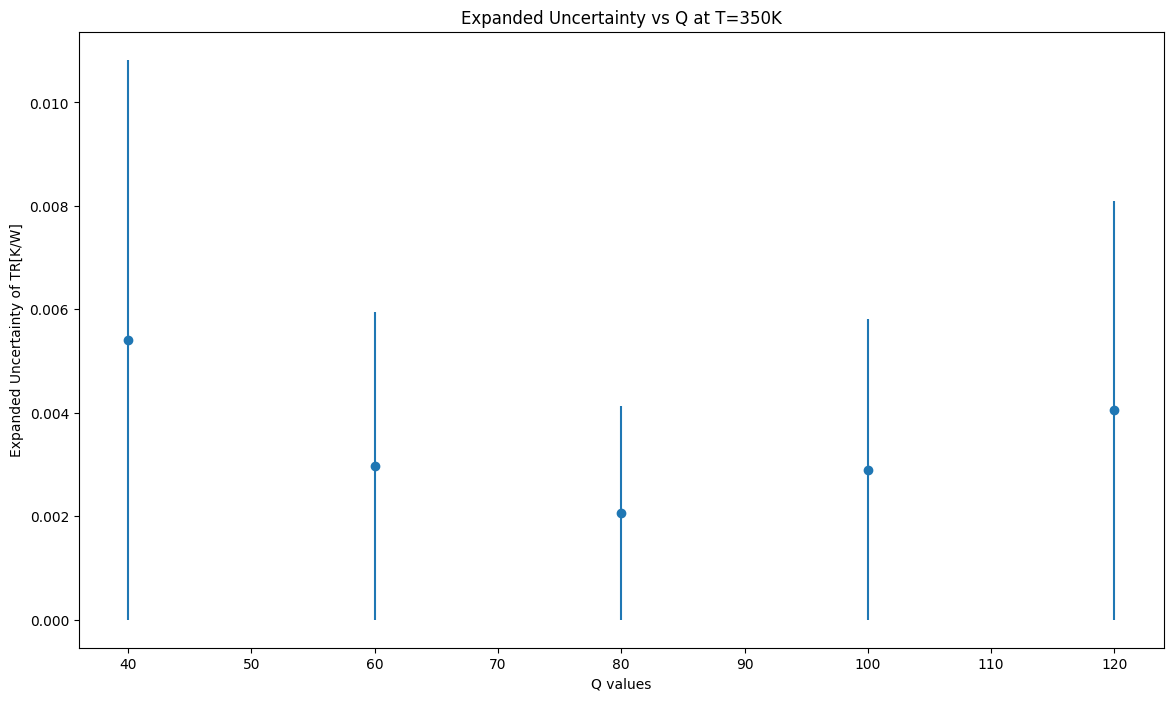

In [52]:
# plot expanded uncertainty for TR[K/W] at filtered temperature and Q
# X axis Q values and y axis expanded uncertainty of TR[K/W] errorbar

import matplotlib.pyplot as plt
Q_values = [40, 60, 80, 100, 120]

expanded_uncertainties = [
    expanded_uncertainty(df_Q40_DIW_a90_b0_T_TR),
    expanded_uncertainty(df_Q60_DIW_a90_b0_T_TR),
    expanded_uncertainty(df_Q80_DIW_a90_b0_T_TR),
    expanded_uncertainty(df_Q100_DIW_a90_b0_T_TR),
    expanded_uncertainty(df_Q120_DIW_a90_b0_T_TR)
]

plt.figure(figsize=(14,8))
plt.errorbar(Q_values, expanded_uncertainties, yerr=expanded_uncertainties, fmt='o')
plt.xlabel('Q values')
plt.ylabel('Expanded Uncertainty of TR[K/W]')
plt.title(f'Expanded Uncertainty vs Q at T={t}K')
plt.show()
